In [3]:
pip install opencv-python

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
import cv2

In [5]:
image=cv2.imread("three.jpg")

In [6]:
import os

In [7]:
print(os.path.exists("three.jpg"))

False


In [8]:
image=cv2.imread(r"C:\Users\adars\Desktop\three.jpeg")

(np.float64(-0.5), np.float64(1599.5), np.float64(1278.5), np.float64(-0.5))

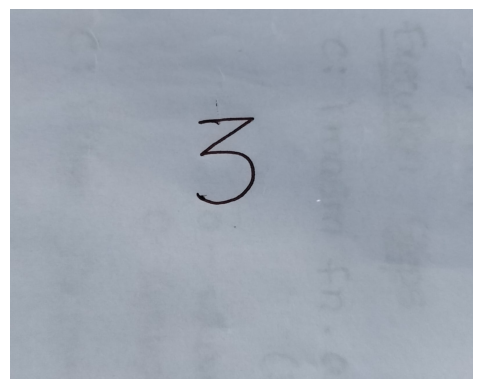

In [9]:
import matplotlib.pyplot as plt
plt.imshow(image)
plt.axis('off')

In [10]:
resized=cv2.resize(image,(28,28))

In [11]:
print(resized.shape)

(28, 28, 3)


In [12]:
gray=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)

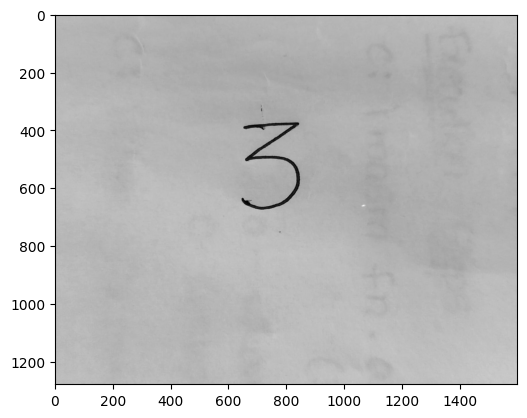

In [13]:
plt.imshow(gray,cmap='gray')

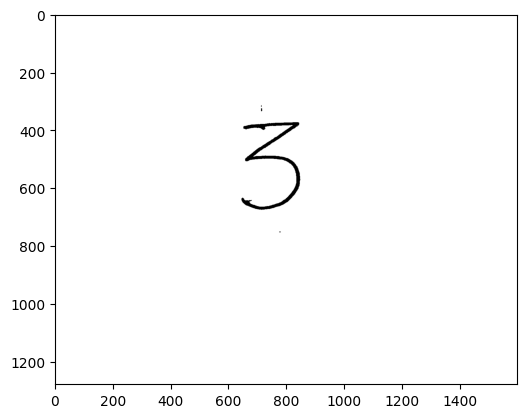

In [14]:
_,threshold = cv2.threshold(
    gray,
    127,
    255,
    cv2.THRESH_BINARY
)
plt.imshow(threshold,cmap='gray')

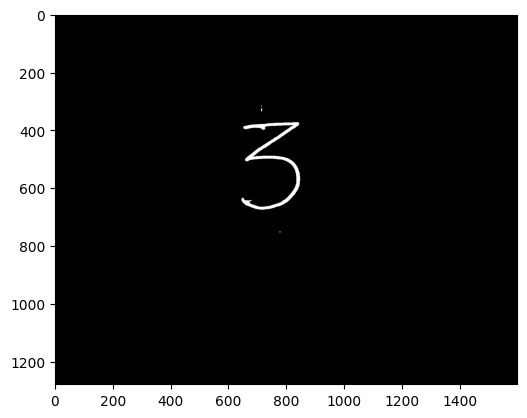

In [15]:
black_threshold = cv2.bitwise_not(threshold)
plt.imshow(black_threshold,cmap='gray')

In [16]:
contours, hierarchy = cv2.findContours(
    cv2.bitwise_not(threshold),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)
print(len(contours))

4


In [17]:
print(contours)

(array([[[775, 752]],

       [[775, 753]],

       [[776, 754]],

       [[778, 754]],

       [[779, 753]],

       [[779, 752]]], dtype=int32), array([[[821, 374]],

       [[820, 375]],

       [[790, 375]],

       ...,

       [[842, 375]],

       [[841, 375]],

       [[840, 374]]], shape=(726, 1, 2), dtype=int32), array([[[712, 326]],

       [[712, 335]],

       [[714, 335]],

       [[715, 334]],

       [[715, 331]],

       [[714, 330]],

       [[715, 329]],

       [[715, 327]],

       [[714, 326]]], dtype=int32), array([[[713, 315]],

       [[712, 316]],

       [[712, 320]],

       [[713, 320]]], dtype=int32))


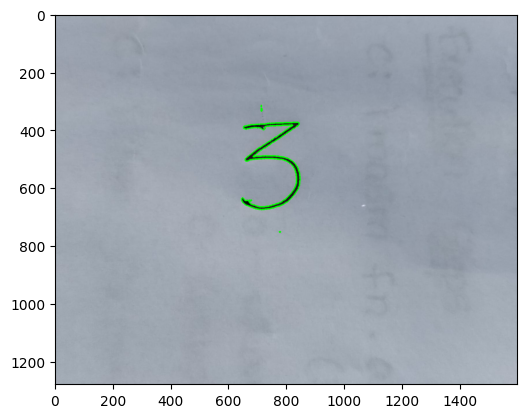

In [18]:
drawing_image = image.copy()
cv2.drawContours(
    drawing_image,
    contours,
    -1,
    (0,255,0),
    3
)
plt.imshow(drawing_image)

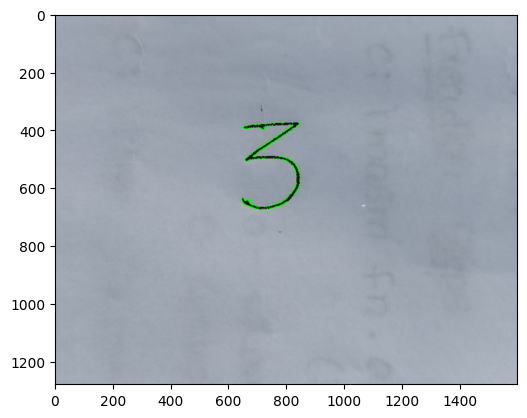

In [19]:
final_contour = None
max_area =0
for contour in contours:
    area = cv2.contourArea(contour)
    if area > max_area:
        max_area = area
        final_contour = contour
drawing_image = image.copy()
cv2.drawContours(
    drawing_image,
    final_contour,
    -1,
    (0,255,0),
    4
)
plt.imshow(drawing_image)

In [78]:
print(final_contour)

[[[821 374]]

 [[820 375]]

 [[790 375]]

 ...

 [[842 375]]

 [[841 375]]

 [[840 374]]]


In [20]:
x, y, w, h = cv2.boundingRect(final_contour)
print(x,y,w,h)

644 374 204 303


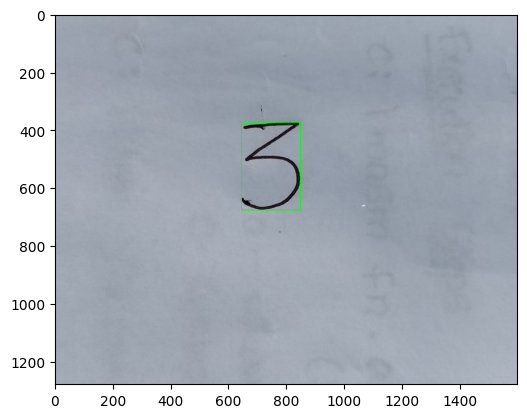

In [21]:
cv2.rectangle(
            image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )
plt.imshow(image,cmap='gray')

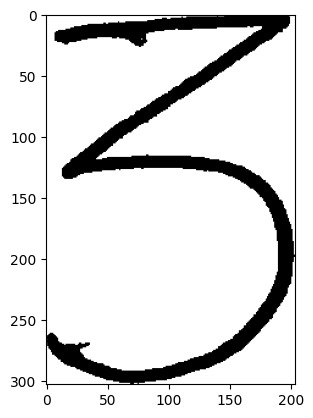

In [22]:
cropped = threshold[y:y+h, x:x+w]
plt.imshow(cropped,cmap='gray')

In [23]:
cropped.shape

(303, 204)

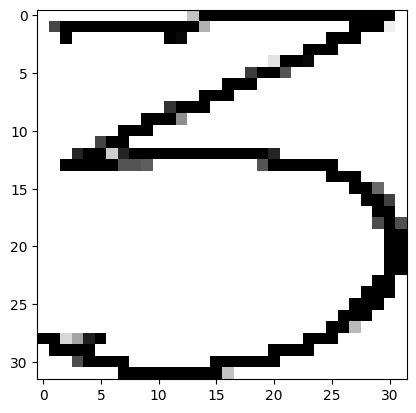

In [24]:
resized = cv2.resize(cropped,(32,32))
plt.imshow(resized,cmap='gray')

In [25]:
print(resized)

[[255 255 255 ...   0   0 255]
 [255  71   0 ...   0 239 255]
 [255 255   0 ... 255 255 255]
 ...
 [255   0   0 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]]


In [26]:
features=resized.flatten()

In [27]:
features.shape

(1024,)

In [28]:
pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [29]:
from tensorflow.keras.datasets import mnist
(x_train,y_train),(x_test,y_test)=mnist.load_data()

In [30]:
print(x_train.shape)

(60000, 28, 28)


In [31]:
print(y_train.shape)

(60000,)


In [32]:
x_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [33]:
y_train[0]

np.uint8(5)

In [34]:
x_train=x_train.reshape(x_train.shape[0],-1)

In [35]:
x_test=x_test.reshape(x_test.shape[0],-1)

In [36]:
print(x_train.shape)

(60000, 784)


In [37]:
print(x_test.shape)

(10000, 784)


In [38]:
x_train=x_train/255.0
x_test=x_test/255.0

In [39]:
x_train_small = x_train[:10000]
y_train_small = y_train[:10000]

In [40]:
pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [41]:
from sklearn.svm import SVC

In [42]:
model=SVC(kernel="rbf")

In [43]:
model.fit(x_train_small,y_train_small)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [44]:
accuracy=model.score(x_test,y_test)
print("Accuracy:",accuracy)

Accuracy: 0.9594


In [45]:
import cv2

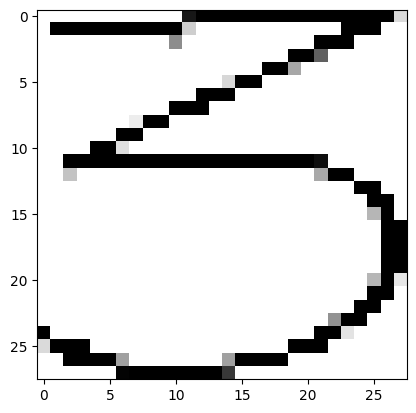

In [46]:
resized=cv2.resize(cropped,(28,28))
plt.imshow(resized,cmap="gray")

In [47]:
features=resized.flatten()
print(features.shape)

(784,)


In [48]:
features=features/255.0

In [49]:
features=features.reshape(1,-1)

In [50]:
print(features.shape)

(1, 784)


In [51]:
prediction=model.predict(features)

In [52]:
print("predictes_digit:",prediction[0])

predictes_digit: 2


In [53]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(x_train[:1000])

correlation = df.corr()


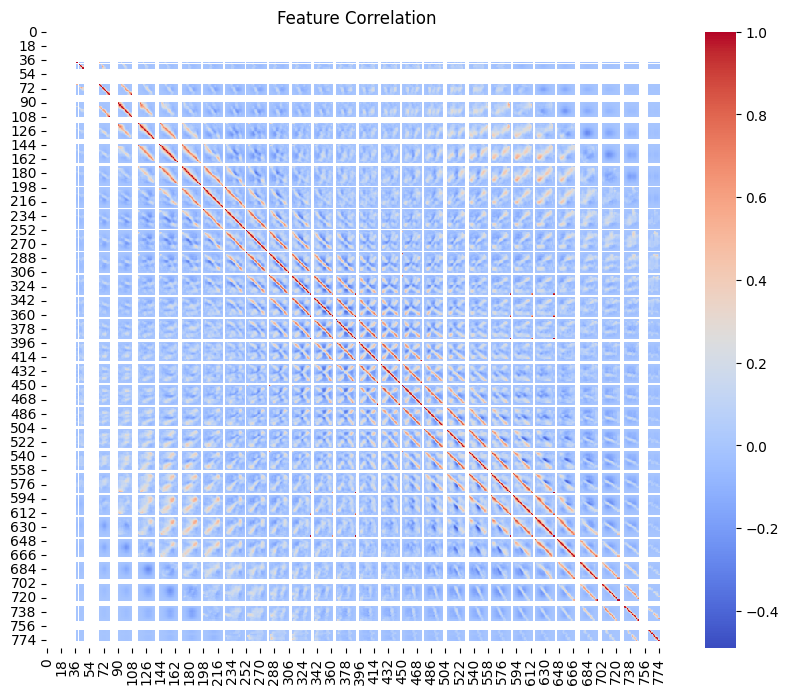

In [56]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.corr(),
    cmap="coolwarm"
)

plt.title("Feature Correlation")
plt.show()

In [58]:
x_train_small1 = x_train[:30000]
y_train_small1 = y_train[:30000]

In [60]:
model1=SVC(kernel="rbf")

In [64]:
model1.fit(x_train_small1,y_train_small1)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [65]:
accuracy=model1.score(x_test,y_test)
print("Accuracy:",accuracy)

Accuracy: 0.9742


In [74]:
prediction1=model1.predict(features)

In [76]:
print(prediction1[0])

2


In [77]:
prediction1.shape

(1,)

In [1]:
!git init

Initialized empty Git repository in C:/Users/adars/.git/
